<a href="https://colab.research.google.com/github/SarahiVargas127/Simulacion-Estocastica/blob/main/Tarea3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 3. Simulación Computacional y Análisis de Resultados
## Simulación Monte Carlo del contenido de carbono fijo (%) del carbón vegetal de especies de bosque templado.

**Universidad Juárez del Estado de Durango (UJED)**  

**Facultad de Ciencias Exactas · Maestría en Estadística Aplicada**  

**Asignatura:** Simulación Estocástica  

**Docente:** Dr. Gerónimo Quiñónez-Barraza

**Alumna:** Angeles Sarahí Vargas Gutiérrez

**Fecha:** 21 de noviembre del 2026

> **Nota sobre los datos:** la base de datos utilizada en esta tarea es **propia**. Corresponde a mediciones de laboratorio realizadas por mí (densidad y análisis proximal de madera de especies de bosque templado). No es un conjunto de datos público ni fue tomado de otra fuente.

## 1. Descripción del problema

**Contexto.** El carbón vegetal se usa como combustible y su calidad depende en buena parte de su **contenido de carbono fijo (CF, %)**: a mayor CF, mayor aprovechamiento energético. En mi base de datos propia, el CF se obtuvo del análisis proximal de madera carbonizada de especies de bosque templado, con la fórmula:

$$CF = 100 - (CH + MV + CC)$$

donde CH es el contenido de humedad, MV la materia volátil y CC el contenido de cenizas (todos en %).

**Datos disponibles.** 105 mediciones de CF (35 muestras con 3 repeticiones cada una) de 16 grupos de especies.

**Objetivo.** Simular valores de CF con el método Monte Carlo para:
1. estimar la media del CF y la incertidumbre de esa estimación (intervalo de confianza del 95 %), y
2. estimar la probabilidad de que una pieza de carbón alcance una calidad alta (CF ≥ 70 %) o baja (CF < 50 %).

**Variables.**
- *Variable de interés:* carbono fijo, CF (%), variable continua.
- *Parámetros estimados a partir de los datos:* media y desviación estándar muestrales de CF.
- *Umbrales de calidad:* 70 % (alta) y 50 % (baja). Son valores de referencia que fijé yo con fines de análisis; pueden cambiarse en el código.

**Modelo propuesto.** CF ~ Normal(μ, σ), con μ y σ estimados de los datos observados. Se verifica este supuesto en la sección 3.

## 2. Configuración y carga de datos

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

SEMILLA = 42      # semilla solicitada en la tarea
N_SIM = 1000      # número de valores simulados (mínimo 1,000)
UMBRAL_ALTO = 70  # CF >= 70 % se considera calidad alta
UMBRAL_BAJO = 50  # CF < 50 % se considera calidad baja

In [2]:
datos_csv = """
muestra,carbono_fijo
As1m1 - 1,51.4054
As1m1 - 2,59.8245
As1m1 - 3,65.4377
As1m2 - 1,67.9143
As1m2 - 2,73.9755
As1m2 - 3,74.5339
As1m3 - 1,53.1759
As1m3 - 2,62.7437
As1m3 - 3,62.382
As2m1 - 1,58.0489
As2m1 - 2,63.3502
As2m1 - 3,66.1742
As3m1 - 1,28.3242
As3m1 - 2,45.5508
As3m1 - 3,45.2998
Ma1m1 - 1,74.155
Ma1m1 - 2,77.6425
Ma1m1 - 3,81.1474
Ma1m2 - 1,54.1398
Ma1m2 - 2,62.1732
Ma1m2 - 3,64.0942
Ma1m3 - 1,57.9192
Ma1m3 - 2,52.204
Ma1m3 - 3,72.6765
Ma1m4 - 1,61.0647
Ma1m4 - 2,51.3631
Ma1m4 - 3,60.5131
P1m1 - 1,58.0977
P1m1 - 2,51.149
P1m1 - 3,55.9359
P1m2 - 1,38.0095
P1m2 - 2,51.8424
P1m2 - 3,56.9196
P1m3 - 1,50.6538
P1m3 - 2,37.8688
P1m3 - 3,44.3003
P1m4 - 1,45.8486
P1m4 - 2,55.0312
P1m4 - 3,51.4607
Q1m1 - 1,62.5425
Q1m1 - 2,66.7318
Q1m1 - 3,57.164
Q1m2 - 1,65.1929
Q1m2 - 2,55.5438
Q1m2 - 3,74.2611
Q2m1 - 1,70.9636
Q2m1 - 2,72.3331
Q2m1 - 3,71.8555
Q3m1 - 1,41.0162
Q3m1 - 2,54.2066
Q3m1 - 3,58.4425
Q4m1 - 1,53.4344
Q4m1 - 2,61.1628
Q4m1 - 3,58.3111
Q4m2 - 1,57.5047
Q4m2 - 2,66.4716
Q4m2 - 3,63.0996
Q4m3 - 1,62.5829
Q4m3 - 2,67.0229
Q4m3 - 3,71.8604
Q5m1 - 1,56.4818
Q5m1 - 2,68.0882
Q5m1 - 3,64.2534
Q5m2 - 1,58.2623
Q5m2 - 2,66.5108
Q5m2 - 3,67.8599
Q5m3 - 1,53.392
Q5m3 - 2,60.1147
Q5m3 - 3,63.8845
Q5m4 - 1,48.0161
Q5m4 - 2,55.8541
Q5m4 - 3,54.7256
QP1m1 - 1,60.3489
QP1m1 - 2,61.3938
QP1m1 - 3,66.293
QP2m3 - 1,58.3271
QP2m3 - 2,63.0745
QP2m3 - 3,68.691
QP4m1 - 1,56.8885
QP4m1 - 2,58.6234
QP4m1 - 3,56.202
QP5m1 - 1,39.3356
QP5m1 - 2,44.8232
QP5m1 - 3,43.6692
QP5m2 - 1,61.0149
QP5m2 - 2,62.6356
QP5m2 - 3,66.4124
QP5m3 - 1,62.9899
QP5m3 - 2,62.1751
QP5m3 - 3,64.8177
QP6m1 - 1,58.0381
QP6m1 - 2,53.9463
QP6m1 - 3,68.1845
QP6m2 - 1,50.7642
QP6m2 - 2,53.2107
QP6m2 - 3,55.8587
T1m1 - 1,61.2983
T1m1 - 2,70.4497
T1m1 - 3,63.0456
T1m2 - 1,73.9617
T1m2 - 2,81.2238
T1m2 - 3,83.4949
T1m3 - 1,50.8143
T1m3 - 2,62.8555
T1m3 - 3,67.4959
"""

In [3]:
# Los datos están incluidos en el notebook para que se ejecute sin archivos externos.
# Si prefieres leerlos del repositorio: df = pd.read_csv("carbono_fijo.csv")
df = pd.read_csv(io.StringIO(datos_csv))
cf_obs = df["carbono_fijo"].to_numpy()

print("Mediciones observadas:", len(cf_obs))
print("Valores faltantes:", int(df["carbono_fijo"].isna().sum()))
display(df.head())

Mediciones observadas: 105
Valores faltantes: 0


,muestra,carbono_fijo
0,As1m1 - 1,51.4054
1,As1m1 - 2,59.8245
2,As1m1 - 3,65.4377
3,As1m2 - 1,67.9143
4,As1m2 - 2,73.9755


## 3. Parámetros observados y verificación del supuesto de normalidad
Se calculan la media y la desviación estándar de los datos observados y se aplica la prueba de Shapiro-Wilk (H₀: los datos provienen de una distribución normal).

In [4]:
mu = cf_obs.mean()
sigma = cf_obs.std(ddof=1)
w, p_shapiro = stats.shapiro(cf_obs)

print(f"Media observada (mu):        {mu:.2f} %")
print(f"Desviación estándar (sigma): {sigma:.2f} %")
print(f"Sesgo: {stats.skew(cf_obs):.2f} | Curtosis (exceso): {stats.kurtosis(cf_obs):.2f}")
print(f"Shapiro-Wilk: W = {w:.3f}, valor p = {p_shapiro:.3f}")

Media observada (mu):        59.87 %
Desviación estándar (sigma): 9.79 %
Sesgo: -0.29 | Curtosis (exceso): 0.53
Shapiro-Wilk: W = 0.988, valor p = 0.450


Con un valor p de aproximadamente 0.45 (mayor que 0.05) **no se rechaza la normalidad**, y el sesgo y la curtosis son cercanos a cero. Por ello se considera razonable modelar el CF con una distribución normal.

## 4. Simulación Monte Carlo
Se generan 1,000 valores aleatorios de una Normal(μ, σ) con semilla 42.

In [5]:
np.random.seed(SEMILLA)
cf_sim = np.random.normal(loc=mu, scale=sigma, size=N_SIM)

print("Valores simulados:", cf_sim.size)
print("Primeros 5 valores:", np.round(cf_sim[:5], 2))

Valores simulados: 1000
Primeros 5 valores: [64.73 58.51 66.21 74.78 57.57]


## 5. Análisis estadístico
Media, desviación estándar, mínimo, máximo e intervalo de confianza del 95 % para la media (con distribución t de Student).

In [6]:
def resumen(v):
    n = len(v)
    media = v.mean()
    sd = v.std(ddof=1)
    error_est = sd / np.sqrt(n)
    t_crit = stats.t.ppf(0.975, df=n - 1)
    return {
        "n": n,
        "Media": media,
        "Desviación estándar": sd,
        "Mínimo": v.min(),
        "Máximo": v.max(),
        "IC 95 % inferior": media - t_crit * error_est,
        "IC 95 % superior": media + t_crit * error_est,
    }

tabla = pd.DataFrame({
    "Simulación (n = 1,000)": resumen(cf_sim),
    "Datos observados (n = 105)": resumen(cf_obs),
}).round(2)
tabla.index.name = "Estadístico"
display(tabla)

tabla.to_csv("resultados_estadisticos.csv")

,"Simulación (n = 1,000)",Datos observados (n = 105)
Estadístico,,
n,1000.00,105.00
Media,60.05,59.87
Desviación estándar,9.59,9.79
Mínimo,28.13,28.32
Máximo,97.58,83.49
IC 95 % inferior,59.46,57.97
IC 95 % superior,60.65,61.76


### Probabilidades de calidad
Proporción de valores simulados que superan o no alcanzan los umbrales, comparada con la probabilidad teórica de la Normal(μ, σ) y con la proporción observada.

In [7]:
prob = pd.DataFrame({
    "Simulada": [(cf_sim >= UMBRAL_ALTO).mean(), (cf_sim < UMBRAL_BAJO).mean()],
    "Teórica (Normal)": [1 - stats.norm.cdf(UMBRAL_ALTO, mu, sigma),
                         stats.norm.cdf(UMBRAL_BAJO, mu, sigma)],
    "Observada": [(cf_obs >= UMBRAL_ALTO).mean(), (cf_obs < UMBRAL_BAJO).mean()],
}, index=[f"P(CF >= {UMBRAL_ALTO} %)", f"P(CF < {UMBRAL_BAJO} %)"])
display((prob * 100).round(1).add_suffix(" (%)"))

fuera = int(((cf_sim < 0) | (cf_sim > 100)).sum())
print("Valores simulados fuera del rango físico [0, 100]:", fuera)

,Simulada (%),Teórica (Normal) (%),Observada (%)
P(CF >= 70 %),14.8,15.0,14.3
P(CF < 50 %),14.3,15.7,11.4


Valores simulados fuera del rango físico [0, 100]: 0


### Contexto: variación entre grupos de especies (datos observados)

In [8]:
df["grupo"] = df["muestra"].str.extract(r"^([A-Za-z]+\d?)m")[0]
por_grupo = df.groupby("grupo")["carbono_fijo"].agg(["count", "mean"]).round(1)
por_grupo.columns = ["n", "CF medio (%)"]
display(por_grupo.T)

grupo,As1,As2,As3,Ma1,P1,Q1,Q2,Q3,Q4,Q5,QP1,QP2,QP4,QP5,QP6,T1
n,9.0,3.0,3.0,12.0,12.0,6.0,3.0,3.0,9.0,12.0,3.0,3.0,3.0,9.0,6.0,9.0
CF medio (%),63.5,62.5,39.7,64.1,49.8,63.6,71.7,51.2,62.4,59.8,62.7,63.4,57.2,56.4,56.7,68.3


## 6. Gráficas

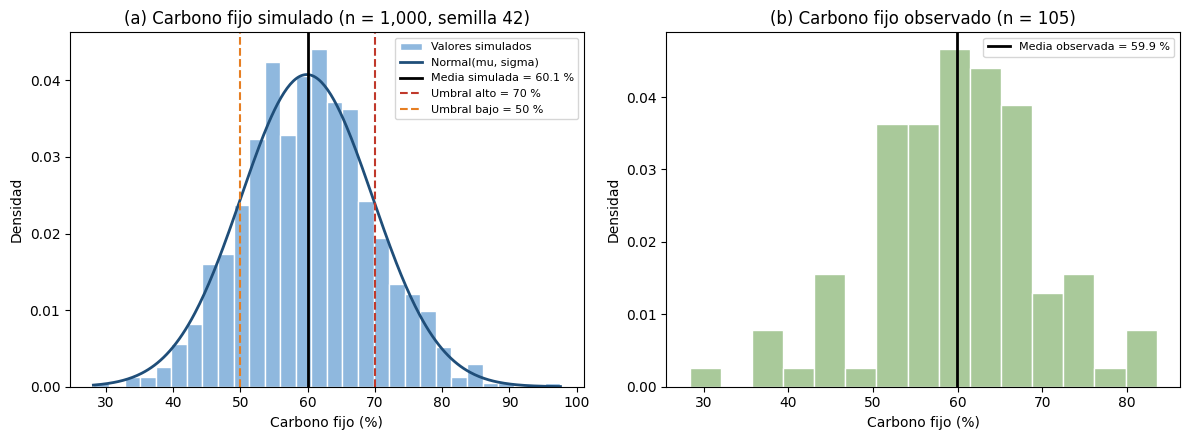

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) Histograma de los valores simulados
ax[0].hist(cf_sim, bins=30, density=True, color="#8FB8DE", edgecolor="white", label="Valores simulados")
xs = np.linspace(cf_sim.min(), cf_sim.max(), 300)
ax[0].plot(xs, stats.norm.pdf(xs, mu, sigma), color="#1F4E79", lw=2, label="Normal(mu, sigma)")
ax[0].axvline(cf_sim.mean(), color="black", lw=2, label=f"Media simulada = {cf_sim.mean():.1f} %")
ax[0].axvline(UMBRAL_ALTO, color="#C0392B", ls="--", label=f"Umbral alto = {UMBRAL_ALTO} %")
ax[0].axvline(UMBRAL_BAJO, color="#E67E22", ls="--", label=f"Umbral bajo = {UMBRAL_BAJO} %")
ax[0].set_title("(a) Carbono fijo simulado (n = 1,000, semilla 42)")
ax[0].set_xlabel("Carbono fijo (%)")
ax[0].set_ylabel("Densidad")
ax[0].legend(fontsize=8)

# (b) Histograma de los datos observados
ax[1].hist(cf_obs, bins=15, density=True, color="#A9C99A", edgecolor="white")
ax[1].axvline(cf_obs.mean(), color="black", lw=2, label=f"Media observada = {cf_obs.mean():.1f} %")
ax[1].set_title("(b) Carbono fijo observado (n = 105)")
ax[1].set_xlabel("Carbono fijo (%)")
ax[1].set_ylabel("Densidad")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("histograma_carbono_fijo.png", dpi=150)
plt.show()

## 7. Interpretación

- **Valor central y variabilidad.** El carbono fijo simulado tiene una media de 60.05 % y una desviación estándar de 9.59 puntos porcentuales, con valores entre 28.1 % y 97.6 %. Esto es consistente con los datos observados (media de 59.87 %, desviación de 9.79). Es decir, el carbón de estas especies tiene en promedio alrededor de 60 % de carbono fijo, pero con una dispersión considerable entre piezas.
- **Incertidumbre de la media.** El IC del 95 % para la media simulada es [59.46, 60.65]. Ese intervalo es angosto sobre todo porque se simularon 1,000 valores: su amplitud depende del tamaño de la simulación y no de la incertidumbre real del fenómeno. La incertidumbre real se refleja mejor en el IC calculado con los datos observados (n = 105): [57.97, 61.76]. Con 95 % de confianza, el CF medio verdadero del carbón de estas especies se encuentra en ese rango.
- **Probabilidades de calidad.** Con el modelo, aproximadamente 14.8 % de las piezas alcanzaría CF ≥ 70 % y 14.3 % tendría CF < 50 %. Estos valores coinciden razonablemente con la probabilidad teórica de la Normal (15.0 % y 15.7 %) y con la proporción observada (14.3 % y 11.4 %).
- **Posible uso en decisiones.** Si se buscara un carbón de alta calidad, el resultado indica que solo cerca de 1 de cada 7 piezas llegaría al umbral de 70 %, por lo que convendría seleccionar el material o los grupos de especies con mejor desempeño. La tabla por grupos sugiere que el CF medio varía entre grupos de especies, aunque varios tienen solo 3 mediciones, por lo que esta diferencia debe tomarse con cautela. Si se confirmara, mezclar todas las especies contribuiría a aumentar la dispersión.

**Limitaciones.** (1) El modelo normal trata todas las especies como una sola población; la simulación llega a 97.6 %, un valor mayor al máximo observado (83.5 %), porque la normal tiene colas que los datos reales no muestran. (2) Las 105 mediciones provienen de 35 muestras con 3 repeticiones, por lo que no son totalmente independientes y el IC observado podría ser algo optimista. (3) Los umbrales de 70 % y 50 % son valores de referencia propuestos para este ejercicio.

## 8. Conclusión
La simulación Monte Carlo con semilla 42 (1,000 valores) reproduce bien la distribución del carbono fijo de mi base de datos propia: una media cercana a 60 %, una desviación de aproximadamente 9.6 puntos y una probabilidad cercana a 15 % de obtener carbón de calidad alta (CF ≥ 70 %). El intervalo de confianza del 95 % de los datos observados ([57.97, 61.76]) cuantifica la incertidumbre sobre la media. Como mejora futura, conviene simular por grupo de especies para obtener estimaciones más específicas.